In [1]:
import os

# Paste your username and key between the quotes below
os.environ['KAGGLE_USERNAME'] = "kayyummongal"
os.environ['KAGGLE_KEY'] = "KGAT_38b71fe49bbe80383f174b42a05f968c"

In [2]:
!kaggle datasets download -d gamalasran/physionet-challenge-2020 --unzip -p /content/physionet-data

Dataset URL: https://www.kaggle.com/datasets/gamalasran/physionet-challenge-2020
License(s): ODC Attribution License (ODC-By)
100% 4.49G/4.49G [03:29<00:00, 23.0MB/s]



# ECG Signal Classification Using a Hybrid CNN-RNN Model (PTB-XL)
Run the cells top to bottom. Step 7 has a `QUICK_TEST` switch: `True` = fast check (about 1 min), `False` = real training.

In [3]:
import os, re, glob, math, time, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from scipy.io import loadmat
from scipy.signal import butter, sosfiltfilt, resample_poly

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import (roc_auc_score, accuracy_score, precision_score,
                             recall_score, f1_score, confusion_matrix,
                             ConfusionMatrixDisplay)

## Step 1: Device check


In [4]:
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"      # mixed precision only works on GPU
print("Device:", DEVICE)
if USE_AMP:
    print("GPU:", torch.cuda.get_device_name(0))
    print("VRAM:", round(torch.cuda.get_device_properties(0).total_memory/1024**3, 2), "GB")

Device: cuda
GPU: Tesla T4
VRAM: 14.56 GB


## Step 2: Settings

In [31]:
DATA_DIR  = r"/content/physionet-data/classification-of-12-lead-ecgs-the-physionetcomputing-in-cardiology-challenge-2020-1.0.2/training/ptb-xl"      # CHANGE THIS if needed
CACHE_DIR = "cache"


MAX_RECORDS = None      # None = all records
TARGET_FS   = 200       # every ECG is resampled to 200 Hz
SECONDS     = 10
N_SAMPLES   = TARGET_FS * SECONDS

# --- segmentation ---
SEG_SECONDS = 10                # try 2 as a separate experiment
SEG_LEN     = TARGET_FS * SEG_SECONDS
SEG_STRIDE  = SEG_LEN if SEG_SECONDS == SECONDS else SEG_LEN // 2                      # for SEG_SECONDS = 2 use TARGET_FS (50% overlap)
N_SEGS      = (N_SAMPLES - SEG_LEN) // SEG_STRIDE + 1

N_CLASSES   = 10
SEED        = 42

MODEL_NAME  = "hybrid"  # "hybrid" = your project model, "fast" = tiny model for quick tests
QUICK_TEST  = False     # True = small quick run, False = full training
BATCH       = 256
EPOCHS      = 40

os.makedirs(CACHE_DIR, exist_ok=True)
np.random.seed(SEED)
torch.manual_seed(SEED);

# Readable names for the SNOMED codes (verify against the Challenge's SNOMED mapping file)
CODE_NAMES = {
    "426783006": "Sinus rhythm",
    "39732003":  "Left axis deviation",
    "164865005": "Myocardial infarction",
    "164951009": "Abnormal QRS",
    "164873001": "Left ventricular hypertrophy",
    "164934002": "T wave abnormal",
    "164861001": "Myocardial ischemia",
    "445118002": "Left anterior fascicular block",
    "164884008": "Ventricular ectopics",
    "164889003": "Atrial fibrillation",
}

## Step 3: Read the files
Each recording has a `.hea` header (sampling rate, gains, diagnosis codes) and a `.mat` file (the signal). The raw numbers are divided by the gain to get real millivolts.

In [32]:
def read_header(path):
    with open(path, "r", errors="ignore") as f:
        lines = f.read().splitlines()

    first = lines[0].split()
    n_leads = int(first[1])
    fs = float(first[2])

    gains = []
    for line in lines[1:1+n_leads]:
        token = line.split()[2]
        m = re.search(r"[\d.]+", token)
        gains.append(float(m.group()) if m else 1.0)

    dx = []
    for line in lines:
        m = re.search(r"#\s*(Dx|Diagnosis)[^:]*:\s*(.*)", line, re.I)
        if m:
            dx += [x for x in re.split(r"[,;\s]+", m.group(2)) if x]

    return {"fs": fs, "gains": np.array(gains), "dx": dx}


def load_signal(hea_path):
    info = read_header(hea_path)
    mat_path = hea_path[:-4] + ".mat"
    val = loadmat(mat_path)["val"].astype(np.float32)
    signal = val / info["gains"][:, None]
    return signal, info

## Step 4: Find files and choose the 10 most common diagnoses

In [33]:
hea_files = sorted(glob.glob(os.path.join(DATA_DIR, "**", "*.hea"), recursive=True))
print("Total recordings:", len(hea_files))
if len(hea_files) == 0:
    raise FileNotFoundError("No .hea files found. Check DATA_DIR.")

subset = hea_files[:MAX_RECORDS] if MAX_RECORDS else hea_files

counts = {}
for h in tqdm(subset, desc="Reading headers"):
    for c in read_header(h)["dx"]:
        counts[c] = counts.get(c, 0) + 1

top = sorted(counts.items(), key=lambda x: -x[1])[:N_CLASSES]
CLASSES = [c for c, _ in top]

print("Selected classes:")
for c, n in top:
    print(f"  {c:>10}  {CODE_NAMES.get(c, '?'):32s} {n} records")
CLASS_NAMES = [CODE_NAMES.get(c, c) for c in CLASSES]

Total recordings: 21837


Reading headers:   0%|          | 0/21837 [00:00<?, ?it/s]

Selected classes:
   426783006  Sinus rhythm                     18092 records
   164865005  Myocardial infarction            5261 records
    39732003  Left axis deviation              5146 records
   164951009  Abnormal QRS                     3389 records
   164873001  Left ventricular hypertrophy     2359 records
   164934002  T wave abnormal                  2345 records
   164861001  Myocardial ischemia              2175 records
   445118002  Left anterior fascicular block   1626 records
   164889003  Atrial fibrillation              1514 records
   164884008  Ventricular ectopics             1154 records


## Step 5: Preprocessing (the DSP part)
1. Replace NaN values with 0.
2. Resample to 200 Hz.
3. Band-pass filter 0.5 to 40 Hz. This removes baseline wander (below 0.5 Hz) and muscle noise and 50 Hz mains hum (above 40 Hz), so no separate notch filter is needed.
4. Normalize each lead (mean 0, std 1).
5. Cut or zero-pad to exactly 10 seconds.

In [34]:
SOS = butter(3, [0.5, 40], btype="bandpass", fs=TARGET_FS, output="sos")

def preprocess(sig, fs):
    sig = np.nan_to_num(sig)
    fs = int(round(fs))

    if fs != TARGET_FS:
        g = math.gcd(fs, TARGET_FS)
        sig = resample_poly(sig, TARGET_FS // g, fs // g, axis=1)

    sig = sosfiltfilt(SOS, sig, axis=1)          # zero-phase band-pass

    mean = sig.mean(axis=1, keepdims=True)
    std  = sig.std(axis=1, keepdims=True)
    sig  = (sig - mean) / (std + 1e-6)

    out = np.zeros((12, N_SAMPLES), dtype=np.float16)
    n = min(N_SAMPLES, sig.shape[1])
    out[:, :n] = sig[:, :n]
    return out

In [35]:
def build_dataset():
    tag = str(MAX_RECORDS)
    fx = os.path.join(CACHE_DIR, f"X_{tag}.npy")
    fy = os.path.join(CACHE_DIR, f"Y_{tag}.npy")
    fc = os.path.join(CACHE_DIR, f"classes_{tag}.json")

    # reuse the saved result if it matches the current classes
    if os.path.exists(fx) and os.path.exists(fy) and os.path.exists(fc):
        if json.load(open(fc)) == CLASSES:
            print("Loaded from cache")
            return np.load(fx), np.load(fy)

    X, Y = [], []
    class_index = {c: i for i, c in enumerate(CLASSES)}

    for h in tqdm(subset, desc="Processing ECG"):
        try:
            sig, info = load_signal(h)
            y = np.zeros(len(CLASSES), dtype=np.float32)
            for c in info["dx"]:
                if c in class_index:
                    y[class_index[c]] = 1
            if y.sum() == 0:          # skip records with none of our 10 classes
                continue
            X.append(preprocess(sig, info["fs"]))
            Y.append(y)
        except Exception as e:
            print("Skipped:", h, e)

    X, Y = np.stack(X), np.stack(Y)
    np.save(fx, X); np.save(fy, Y)
    json.dump(CLASSES, open(fc, "w"))
    return X, Y

X, Y = build_dataset()
print("X shape:", X.shape, "(records, leads, samples)")
print("Y shape:", Y.shape, "(records, classes)")
print("Records per class:", dict(zip(CLASS_NAMES, Y.sum(0).astype(int))))

Loaded from cache
X shape: (21254, 12, 2000) (records, leads, samples)
Y shape: (21254, 10) (records, classes)
Records per class: {'Sinus rhythm': np.int64(18092), 'Myocardial infarction': np.int64(5261), 'Left axis deviation': np.int64(5146), 'Abnormal QRS': np.int64(3389), 'Left ventricular hypertrophy': np.int64(2359), 'T wave abnormal': np.int64(2345), 'Myocardial ischemia': np.int64(2175), 'Left anterior fascicular block': np.int64(1626), 'Atrial fibrillation': np.int64(1514), 'Ventricular ectopics': np.int64(1154)}


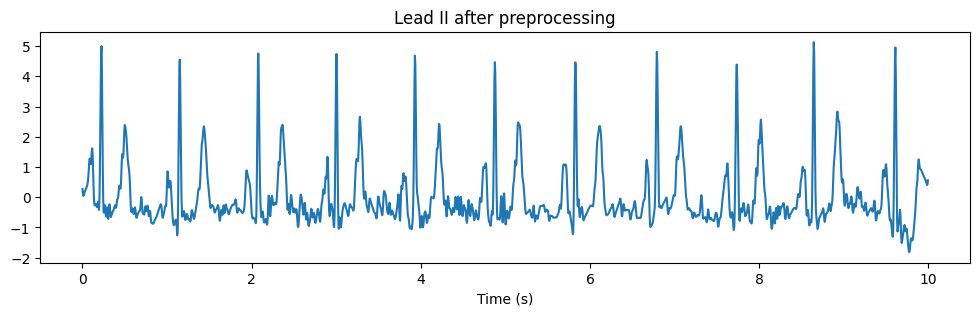

In [36]:
# Look at one preprocessed ECG to make sure it looks right
plt.figure(figsize=(12, 3))
plt.plot(np.arange(N_SAMPLES)/TARGET_FS, X[0][1].astype(np.float32))
plt.title("Lead II after preprocessing"); plt.xlabel("Time (s)")
plt.show()

## Step 6: Train / validation / test split and 1-second segments
The split is done **per record first** (70% train, 15% validation, 15% test). Only after that is each 10 s record cut into ten 1 s windows (200 samples each). This way, segments from the same recording can never appear in both train and test.

Every segment inherits the label of its parent record. All-zero (padding) segments are skipped. The cut is done on the fly from the cached array, so nothing extra is stored in memory.

In [37]:
!pip -q install iterative-stratification
from iterstrat.ml_stratifiers import MultilabelStratifiedShuffleSplit

idx = np.arange(len(X))
Yi  = Y.astype(int)
s1 = MultilabelStratifiedShuffleSplit(n_splits=1, test_size=0.30, random_state=SEED)
train_idx, temp_idx = next(s1.split(idx, Yi))
s2 = MultilabelStratifiedShuffleSplit(n_splits=1, test_size=0.50, random_state=SEED)
v, t = next(s2.split(temp_idx, Yi[temp_idx]))
val_idx, test_idx = temp_idx[v], temp_idx[t]
print("Records  -> Train:", len(train_idx), "Val:", len(val_idx), "Test:", len(test_idx))


class ECGSegmentDataset(Dataset):
    """One item = one segment (12, SEG_LEN) of one record.
    Returns (segment, label, record_id). With train=True the window is jittered
    and the signal gets a small random gain and noise."""
    def __init__(self, X, Y, rec_indices, train=False):
        self.X, self.Y, self.train = X, Y, train
        pairs = []
        for r in rec_indices:
            for s in range(N_SEGS):
                start = s * SEG_STRIDE
                if np.any(X[r, :, start:start + SEG_LEN]):      # skip pure zero-padding
                    pairs.append((r, start))
        self.pairs = np.array(pairs, dtype=np.int64)

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, i):
        r, start = self.pairs[i]
        if self.train:
            shift = np.random.randint(-SEG_LEN // 4, SEG_LEN // 4 + 1)
            start = int(np.clip(start + shift, 0, N_SAMPLES - SEG_LEN))
        x = self.X[r, :, start:start + SEG_LEN].astype(np.float32)
        if self.train:
            x = x * np.random.uniform(0.9, 1.1) + np.random.normal(0, 0.02, x.shape).astype(np.float32)
        y = self.Y[r].astype(np.float32)
        return torch.from_numpy(x), torch.from_numpy(y), int(r)


def make_loaders(tr, va, te, batch):
    pin = DEVICE.type == "cuda"
    tr_ds = ECGSegmentDataset(X, Y, tr, train=True)
    va_ds = ECGSegmentDataset(X, Y, va)
    te_ds = ECGSegmentDataset(X, Y, te)
    print(f"Segments -> Train: {len(tr_ds)}  Val: {len(va_ds)}  Test: {len(te_ds)}  (each {SEG_SECONDS}s, {SEG_LEN} samples)")
    return (DataLoader(tr_ds, batch_size=batch, shuffle=True,  num_workers=2, pin_memory=pin),
            DataLoader(va_ds, batch_size=batch, shuffle=False, num_workers=0, pin_memory=pin),
            DataLoader(te_ds, batch_size=batch, shuffle=False, num_workers=0, pin_memory=pin))

Records  -> Train: 14880 Val: 3172 Test: 3202


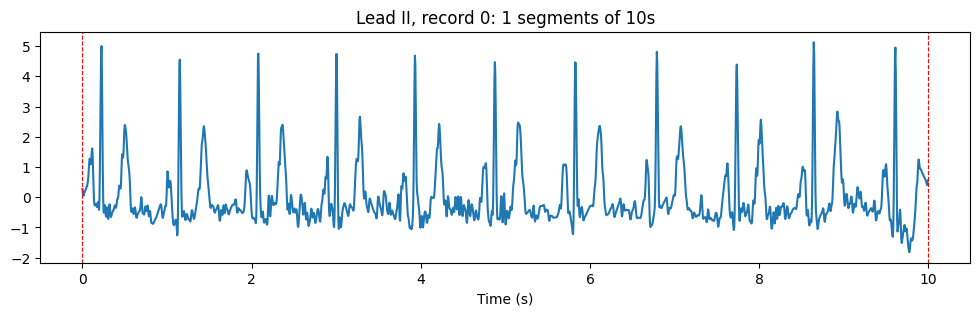

One model input: (12, 2000) (leads, samples)


In [38]:
# Visual check: one record cut into 1-second segments (dashed lines = segment borders)
r = train_idx[0]
t = np.arange(N_SAMPLES) / TARGET_FS
plt.figure(figsize=(12, 3))
plt.plot(t, X[r][1].astype(np.float32))
for s in range(N_SEGS + 1):
    plt.axvline(s * SEG_STRIDE / TARGET_FS, color="r", ls="--", lw=0.8)
plt.title(f"Lead II, record {r}: {N_SEGS} segments of {SEG_SECONDS}s"); plt.xlabel("Time (s)")
plt.show()

xb, yb, rb = ECGSegmentDataset(X, Y, [r])[0]
print("One model input:", tuple(xb.shape), "(leads, samples)")


## Step 7: Models

In [39]:
class SEBlock(nn.Module):
    # Squeeze-and-Excitation: learns which channels matter more
    def __init__(self, ch, r=8):
        super().__init__()
        self.fc1 = nn.Linear(ch, max(ch // r, 1))
        self.fc2 = nn.Linear(max(ch // r, 1), ch)

    def forward(self, x):
        s = x.mean(dim=2)
        s = torch.relu(self.fc1(s))
        s = torch.sigmoid(self.fc2(s))
        return x * s.unsqueeze(2)


class ResSEBlock(nn.Module):
    def __init__(self, in_ch, out_ch, stride=2):
        super().__init__()
        self.conv1 = nn.Conv1d(in_ch, out_ch, 7, stride=stride, padding=3, bias=False)
        self.bn1 = nn.BatchNorm1d(out_ch)
        self.conv2 = nn.Conv1d(out_ch, out_ch, 7, padding=3, bias=False)
        self.bn2 = nn.BatchNorm1d(out_ch)
        self.se = SEBlock(out_ch)
        self.short = nn.Sequential(
            nn.Conv1d(in_ch, out_ch, 1, stride=stride, bias=False),
            nn.BatchNorm1d(out_ch))

    def forward(self, x):
        out = torch.relu(self.bn1(self.conv1(x)))
        out = self.se(self.bn2(self.conv2(out)))
        return torch.relu(out + self.short(x))


class HybridCNNRNN(nn.Module):
    def __init__(self, n_classes):
        super().__init__()
        # multi-kernel CNN: looks at 5, 15 and 25 sample windows at the same time
        self.stem = nn.ModuleList([nn.Conv1d(12, 32, k, padding=k//2) for k in [5, 15, 25]])
        self.stem_bn = nn.BatchNorm1d(96)
        self.blocks = nn.Sequential(ResSEBlock(96, 128), ResSEBlock(128, 128), ResSEBlock(128, 256))
        self.lstm = nn.LSTM(256, 128, batch_first=True, bidirectional=True)
        self.gru  = nn.GRU(256, 128, batch_first=True, bidirectional=True)
        self.head = nn.Sequential(nn.Dropout(0.3), nn.Linear(768, 256), nn.ReLU(),
                                  nn.Dropout(0.3), nn.Linear(256, n_classes))

    def forward(self, x):
        x = torch.cat([conv(x) for conv in self.stem], dim=1)
        x = torch.relu(self.stem_bn(x))
        x = self.blocks(x)
        cnn_feat  = x.mean(dim=2)
        seq = x.permute(0, 2, 1)
        lstm_feat = self.lstm(seq)[0].mean(dim=1)
        gru_feat  = self.gru(seq)[0].mean(dim=1)
        return self.head(torch.cat([cnn_feat, lstm_feat, gru_feat], dim=1))


class FastECGModel(nn.Module):
    # tiny CNN, only for checking that the pipeline runs
    def __init__(self, n_classes):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv1d(12, 32, 7, stride=2, padding=3), nn.BatchNorm1d(32), nn.ReLU(),
            nn.Conv1d(32, 64, 7, stride=2, padding=3), nn.BatchNorm1d(64), nn.ReLU(),
            nn.Conv1d(64, 128, 7, stride=2, padding=3), nn.BatchNorm1d(128), nn.ReLU(),
            nn.AdaptiveAvgPool1d(1))
        self.fc = nn.Linear(128, n_classes)

    def forward(self, x):
        return self.fc(self.features(x).squeeze(-1))


def build_model():
    m = HybridCNNRNN(len(CLASSES)) if MODEL_NAME == "hybrid" else FastECGModel(len(CLASSES))
    return m.to(DEVICE)

model = build_model()
print(MODEL_NAME, "parameters:", sum(p.numel() for p in model.parameters() if p.requires_grad))

hybrid parameters: 2116586


## Step 8: Training and evaluation functions
Optimizer, scheduler and scaler are all created together from the current model, so they cannot get out of sync.

The model sees 1-second segments, but a diagnosis belongs to the whole recording. So `evaluate` returns per-segment probabilities and `aggregate_by_record` averages the segment probabilities of each record into one prediction per record.

In [40]:
AGG, TOPK = "mean", 2      # how segment probabilities are combined: "mean", "max" or "topk"

def make_training_objects(model):
    # softer class weights (sqrt, capped at 4) -> fewer false positives than the old cap of 10
    pos = Y[train_idx].sum(0)
    neg = len(train_idx) - pos
    pw  = torch.tensor(np.clip(np.sqrt(neg / np.maximum(pos, 1)), 1, 4), dtype=torch.float32).to(DEVICE)

    criterion = nn.BCEWithLogitsLoss(pos_weight=pw)
    optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="max", factor=0.5, patience=3)
    scaler    = torch.amp.GradScaler("cuda", enabled=USE_AMP)
    return criterion, optimizer, scheduler, scaler


def train_one_epoch(model, loader, criterion, optimizer, scaler):
    model.train()
    running = 0.0
    for xb, yb, _ in loader:
        xb = xb.to(DEVICE, non_blocking=True)
        yb = yb.to(DEVICE, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device_type=DEVICE.type, enabled=USE_AMP):
            loss = criterion(model(xb), yb)

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(optimizer)
        scaler.update()
        running += loss.item() * len(xb)
    return running / len(loader.dataset)


@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    probs, targets, rec_ids = [], [], []
    for xb, yb, rb in loader:
        out = model(xb.to(DEVICE, non_blocking=True))
        probs.append(torch.sigmoid(out).float().cpu().numpy())
        targets.append(yb.numpy())
        rec_ids.append(rb.numpy())
    return np.concatenate(probs), np.concatenate(targets), np.concatenate(rec_ids)


def aggregate_by_record(probs, targets, rec_ids):
    """Combine the segment probabilities of each record -> one prediction per record."""
    uniq, inv = np.unique(rec_ids, return_inverse=True)
    order  = np.argsort(inv, kind="stable")
    bounds = np.cumsum(np.bincount(inv))[:-1]
    p_groups = np.split(probs[order], bounds)
    t_groups = np.split(targets[order], bounds)
    rec_probs = np.zeros((len(uniq), probs.shape[1]))
    for k, p in enumerate(p_groups):
        if AGG == "max":
            rec_probs[k] = p.max(0)
        elif AGG == "topk":
            rec_probs[k] = np.sort(p, axis=0)[-min(TOPK, len(p)):].mean(0)
        else:
            rec_probs[k] = p.mean(0)
    rec_targets = np.stack([t[0] for t in t_groups])   # all segments of a record share one label
    return rec_probs, rec_targets


def per_class_auc(y_true, y_prob):
    return [roc_auc_score(y_true[:, i], y_prob[:, i]) if 0 < y_true[:, i].sum() < len(y_true) else np.nan
            for i in range(y_true.shape[1])]


def macro_auc(y_true, y_prob):
    a = per_class_auc(y_true, y_prob)
    return float(np.nanmean(a)) if not np.all(np.isnan(a)) else float("nan")


def best_thresholds(y_true, y_prob, n_boot=30, seed=0):
    """Per-class F1-optimal threshold, taken as the median over bootstrap resamples
    of the validation set (more stable than a single pass for rare classes)."""
    rng  = np.random.default_rng(seed)
    grid = np.arange(0.05, 0.95, 0.01)
    n, out = len(y_true), []
    for i in range(y_true.shape[1]):
        y = y_true[:, i].astype(bool); p = y_prob[:, i]
        chosen = []
        for _ in range(n_boot):
            b = rng.integers(0, n, n)
            yb, pb = y[b], p[b]
            pred = pb[:, None] >= grid[None, :]
            tp = (pred &  yb[:, None]).sum(0)
            fp = (pred & ~yb[:, None]).sum(0)
            fn = (~pred & yb[:, None]).sum(0)
            f1 = 2 * tp / np.maximum(2 * tp + fp + fn, 1)
            chosen.append(grid[np.argmax(f1)])
        out.append(np.median(chosen))
    return np.array(out)

## Step 9: Train
With `QUICK_TEST = True` this runs 2 epochs on 200 records, just to prove the code works. **Its AUC means nothing about model quality.** Set it to `False` for the real run.

Training is on 1-second segments. Validation AUC is computed per record (segment probabilities averaged) and that is what picks the best model. The per-segment AUC is printed too, for comparison.

In [41]:
SEEDS    = [42]      # use [42, 43, 44] for a 3-model ensemble (3x training time)
PATIENCE = 8         # stop a run if val AUC hasn't improved for this many epochs

if QUICK_TEST:
    tr, va, te = train_idx[:200], val_idx[:60], test_idx[:60]
    n_epochs = 2
else:
    tr, va, te = train_idx, val_idx, test_idx
    n_epochs = EPOCHS

train_dl, val_dl, test_dl = make_loaders(tr, va, te, BATCH)


def train_model(seed):
    torch.manual_seed(seed); np.random.seed(seed)
    model = build_model()
    criterion, optimizer, scheduler, scaler = make_training_objects(model)
    hist = {"loss": [], "val_auc": [], "val_seg_auc": []}
    best_auc, bad, path = -1.0, 0, f"best_model_{seed}.pt"

    for epoch in range(1, n_epochs + 1):
        t0 = time.time()
        loss = train_one_epoch(model, train_dl, criterion, optimizer, scaler)
        vp, vt, vr = evaluate(model, val_dl)
        seg_auc = macro_auc(vt, vp)
        rp, rt = aggregate_by_record(vp, vt, vr)
        auc = macro_auc(rt, rp)
        score = 0.0 if np.isnan(auc) else auc
        scheduler.step(score)

        hist["loss"].append(loss); hist["val_auc"].append(auc); hist["val_seg_auc"].append(seg_auc)
        if epoch == 1 or score > best_auc:
            best_auc, bad = score, 0
            torch.save(model.state_dict(), path)
        else:
            bad += 1

        print(f"[seed {seed}] Epoch {epoch:2d}/{n_epochs} | loss {loss:.4f} | val AUC (record) {auc:.4f} | val AUC (segment) {seg_auc:.4f} | {time.time()-t0:.0f}s")
        if bad >= PATIENCE:
            print("Early stopping"); break
    return path, hist, best_auc


best_paths, all_hist = [], {}
for s in SEEDS:
    p, h, b = train_model(s)
    best_paths.append(p); all_hist[s] = h
    print(f"Seed {s} best val AUC: {b:.4f}")

history = all_hist[SEEDS[0]]      # used by the plotting cell below

Segments -> Train: 14880  Val: 3172  Test: 3202  (each 10s, 2000 samples)
[seed 42] Epoch  1/40 | loss 0.4915 | val AUC (record) 0.8903 | val AUC (segment) 0.8903 | 18s
[seed 42] Epoch  2/40 | loss 0.3878 | val AUC (record) 0.9186 | val AUC (segment) 0.9186 | 26s
[seed 42] Epoch  3/40 | loss 0.3500 | val AUC (record) 0.9263 | val AUC (segment) 0.9263 | 25s
[seed 42] Epoch  4/40 | loss 0.3293 | val AUC (record) 0.9313 | val AUC (segment) 0.9313 | 18s
[seed 42] Epoch  5/40 | loss 0.3148 | val AUC (record) 0.9341 | val AUC (segment) 0.9341 | 18s
[seed 42] Epoch  6/40 | loss 0.3084 | val AUC (record) 0.9362 | val AUC (segment) 0.9362 | 18s
[seed 42] Epoch  7/40 | loss 0.2949 | val AUC (record) 0.9376 | val AUC (segment) 0.9376 | 19s
[seed 42] Epoch  8/40 | loss 0.2891 | val AUC (record) 0.9408 | val AUC (segment) 0.9408 | 19s
[seed 42] Epoch  9/40 | loss 0.2848 | val AUC (record) 0.9418 | val AUC (segment) 0.9418 | 18s
[seed 42] Epoch 10/40 | loss 0.2772 | val AUC (record) 0.9419 | val AUC

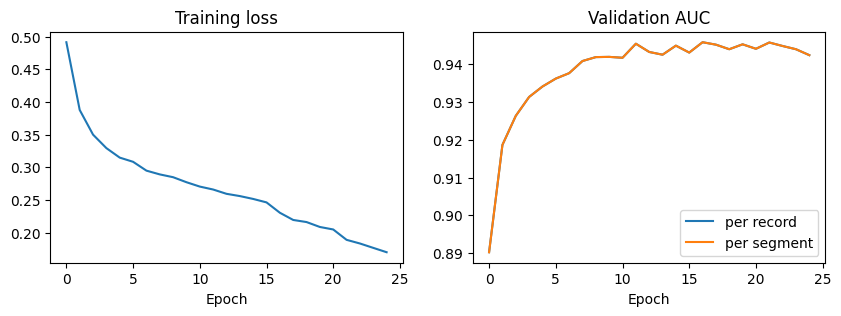

In [42]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
ax[0].plot(history["loss"]);    ax[0].set_title("Training loss")
ax[1].plot(history["val_auc"], label="per record"); ax[1].plot(history["val_seg_auc"], label="per segment")
ax[1].set_title("Validation AUC"); ax[1].legend()
for a in ax: a.set_xlabel("Epoch")
plt.show()

## Step 10: Final test results
Loads the best saved model and reports the metrics from your project plan (accuracy, precision, recall, F1, confusion matrix). The 1-second segment probabilities of each test record are averaged first, so the table below is **per record**, directly comparable to the earlier 10 s model. A prediction counts as "disease present" when its probability is 0.5 or more.

In [43]:
models = []
for p in best_paths:
    m = build_model()
    m.load_state_dict(torch.load(p, map_location=DEVICE))
    models.append(m)

def evaluate_ens(models, loader):
    ps = []
    for m in models:
        p, t, r = evaluate(m, loader)
        ps.append(p)
    return np.mean(ps, axis=0), t, r          # loaders are not shuffled, so order matches

# 1) thresholds are chosen on the validation set
vp, vt, vr = evaluate_ens(models, val_dl)
vp, vt = aggregate_by_record(vp, vt, vr)
THR = best_thresholds(vt.astype(int), vp)
print("Thresholds:", dict(zip(CLASS_NAMES, THR.round(2))))

# 2) applied to the test set (one prediction per record)
sp, st, sr = evaluate_ens(models, test_dl)
print("Segment-level macro AUC:", round(macro_auc(st, sp), 4))
tp, tt = aggregate_by_record(sp, st, sr)
pred = (tp >= THR).astype(int)
tt = tt.astype(int)

aucs = per_class_auc(tt, tp)
rows = []
for i, name in enumerate(CLASS_NAMES):
    rows.append({
        "Class": name,
        "Positives": int(tt[:, i].sum()),
        "Threshold": round(float(THR[i]), 2),
        "Accuracy":  accuracy_score(tt[:, i], pred[:, i]),
        "Precision": precision_score(tt[:, i], pred[:, i], zero_division=0),
        "Recall":    recall_score(tt[:, i], pred[:, i], zero_division=0),
        "F1":        f1_score(tt[:, i], pred[:, i], zero_division=0),
        "AUC":       aucs[i],
    })
results = pd.DataFrame(rows).round(3)
display(results)
print("Macro AUC:", round(macro_auc(tt, tp), 4),
      "| Macro F1:", round(results["F1"].mean(), 4),
      "| Mean accuracy:", round(results["Accuracy"].mean(), 4))

Thresholds: {'Sinus rhythm': np.float64(0.62), 'Myocardial infarction': np.float64(0.48), 'Left axis deviation': np.float64(0.61), 'Abnormal QRS': np.float64(0.6), 'Left ventricular hypertrophy': np.float64(0.45), 'T wave abnormal': np.float64(0.58), 'Myocardial ischemia': np.float64(0.55), 'Left anterior fascicular block': np.float64(0.65), 'Atrial fibrillation': np.float64(0.72), 'Ventricular ectopics': np.float64(0.71)}
Segment-level macro AUC: 0.943


,Class,Positives,Threshold,Accuracy,Precision,Recall,F1,AUC
0,Sinus rhythm,2714,0.62,0.930,0.940,0.980,0.960,0.934
1,Myocardial infarction,789,0.48,0.888,0.753,0.809,0.780,0.941
2,Left axis deviation,772,0.61,0.890,0.732,0.859,0.790,0.950
3,Abnormal QRS,508,0.60,0.877,0.605,0.646,0.625,0.891
4,Left ventricular hypertrophy,354,0.45,0.890,0.501,0.585,0.540,0.890
5,T wave abnormal,352,0.58,0.882,0.474,0.651,0.549,0.907
6,Myocardial ischemia,326,0.55,0.933,0.657,0.724,0.689,0.957
7,Left anterior fascicular block,244,0.65,0.963,0.729,0.828,0.775,0.986
8,Atrial fibrillation,227,0.72,0.978,0.841,0.859,0.850,0.986
9,Ventricular ectopics,173,0.71,0.980,0.779,0.879,0.826,0.988


Macro AUC: 0.943 | Macro F1: 0.7384 | Mean accuracy: 0.9211


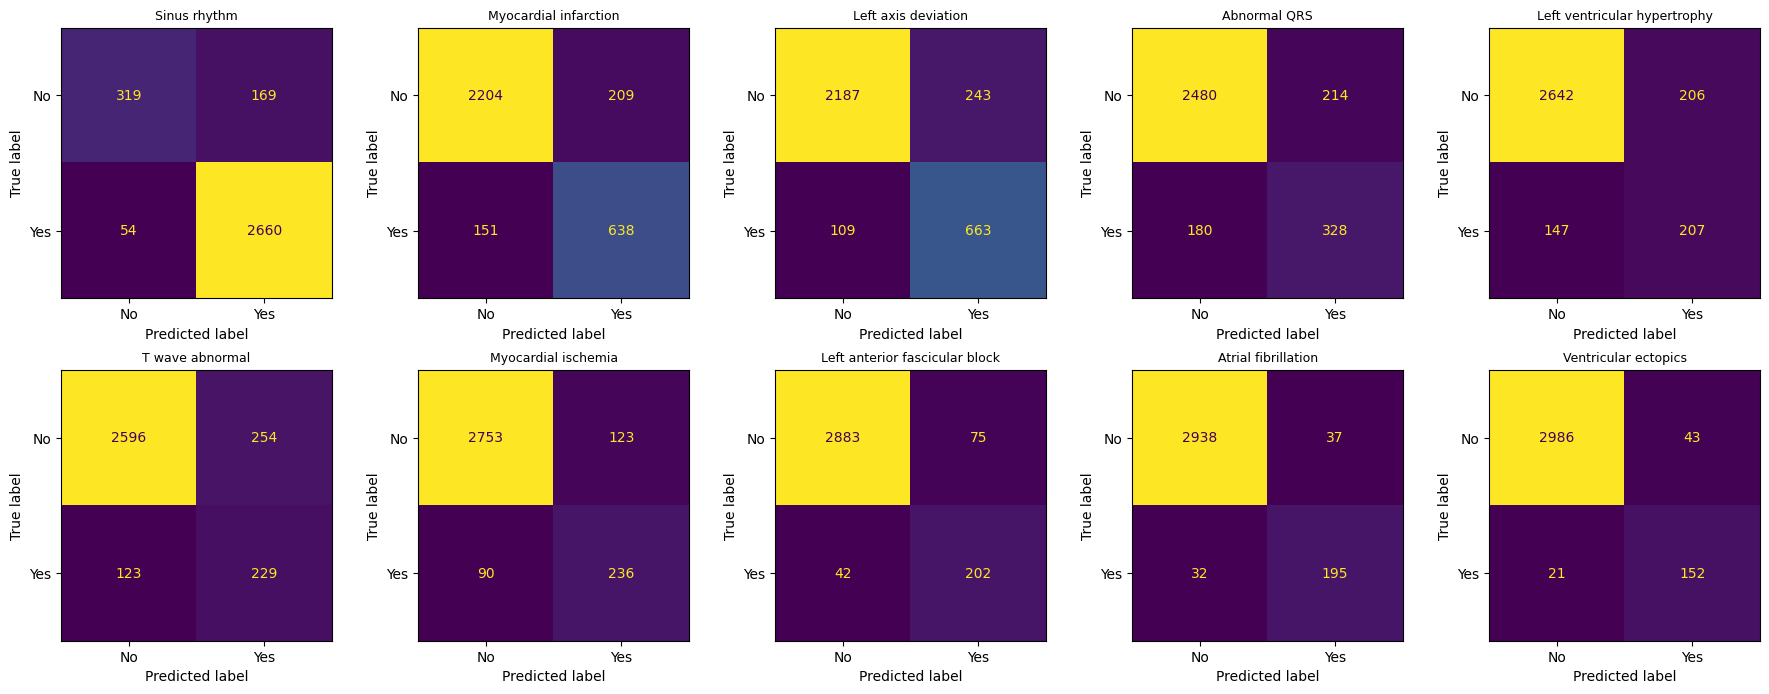

In [44]:
# One confusion matrix per class (2x2: absent / present)
fig, axes = plt.subplots(2, 5, figsize=(18, 7))
for i, ax in enumerate(axes.ravel()):
    cm = confusion_matrix(tt[:, i], pred[:, i], labels=[0, 1])
    ConfusionMatrixDisplay(cm, display_labels=["No", "Yes"]).plot(ax=ax, colorbar=False)
    ax.set_title(CLASS_NAMES[i], fontsize=9)
plt.tight_layout(); plt.show()